## PCA and UMAP

Principal Component analysis first

In [24]:
import pandas as pd, numpy as np
covtype = pd.read_csv('../data/covtype.csv')
covtype

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581007,2396,153,20,85,17,108,240,237,118,837,...,0,0,0,0,0,0,0,0,0,3
581008,2391,152,19,67,12,95,240,237,119,845,...,0,0,0,0,0,0,0,0,0,3
581009,2386,159,17,60,7,90,236,241,130,854,...,0,0,0,0,0,0,0,0,0,3
581010,2384,170,15,60,5,90,230,245,143,864,...,0,0,0,0,0,0,0,0,0,3


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = covtype.drop(columns=['Cover_Type'])  
y = covtype['Cover_Type']                  

X_scaled = StandardScaler().fit_transform(X)   
cormat = pd.DataFrame(X_scaled).corr()

eigen_vals, eigen_vecs = np.linalg.eig(cormat)

#print("condition number", np.sqrt(np.max(evals) / np.min(evals)))

print(eigen_vals)

[ 3.69979412e+00  2.92060370e+00  2.39812238e+00  2.00298084e+00
  3.29870163e-03  1.36096176e-01  1.55694794e-01  1.52108300e+00
  1.46288331e+00  2.51339216e-01  2.88940496e-01  3.26885093e-01
  4.15721221e-01  4.60318958e-01  6.33857939e-01  6.43921234e-01
 -1.83652493e-15  2.50032551e-14  1.22850485e+00  8.05877370e-01
  8.25367463e-01  1.16581733e+00  1.10314469e+00  1.08425197e+00
  1.07408712e+00  1.06742313e+00  1.05475778e+00  9.79692074e-01
  1.03838971e+00  1.03634633e+00  1.03234231e+00  1.02651083e+00
  1.02458414e+00  1.02168464e+00  1.01645513e+00  1.01430828e+00
  1.01348215e+00  1.01026776e+00  1.00915923e+00  1.00781112e+00
  1.00656279e+00  1.00631294e+00  1.00001131e+00  1.00022707e+00
  1.00046257e+00  1.00074063e+00  1.00099603e+00  1.00123837e+00
  1.00230496e+00  1.00303390e+00  1.00437932e+00  1.00376639e+00
  1.00402669e+00  1.00413046e+00]


In [26]:
tot = sum(eigen_vals)
var_exp = [(i / tot) for i in sorted(eigen_vals, reverse=True)]
cum_var_exp = np.cumsum(var_exp)

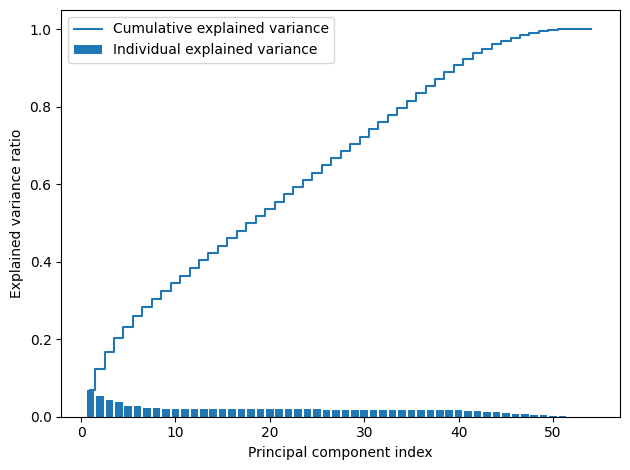

In [27]:
import matplotlib.pyplot as plt

n = len(var_exp)
plt.bar(range(1, n+1), var_exp, align='center',
        label='Individual explained variance')
plt.step(range(1, n+1), cum_var_exp, where='mid',
         label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

Unifrom Maniform Approximation and Projection

In [28]:
import umap
reducer = umap.UMAP()
idx = np.random.RandomState(42).choice(len(X_scaled), size=20000, replace=False)
X_s = X_scaled[idx]
y_s = y.iloc[idx]
umap_comps = reducer.fit_transform(X_s)

c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


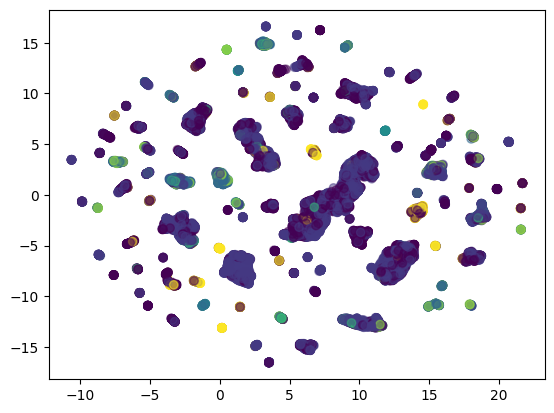

In [29]:
plt.scatter(umap_comps[:,0], umap_comps[:, 1], c=y_s, marker='o', alpha=0.5)

## Classification on the original data compared with PCA- and UMAP-reduced data

The classifier is a **random forest**. It handles the mix of continuous columns (elevation, distances, hillshade) and 0/1 one-hot columns (wilderness area, soil type) well, gives strong results without much tuning, and trains quickly.

How the comparison is set up:
- **Sample:** a stratified random sample of 30,000 rows, because UMAP on all 581,012 rows takes too long. Stratifying keeps the cover type proportions the same as in the full data.
- **Train/test split:** 70% training and 30% test, also stratified.
- **No leakage:** the scaler, PCA and UMAP are all fit on the **training set only** and then used to transform the test set, so nothing about the test set leaks into the features.
- **Hyperparameter:** the forest's `max_depth` is tried at 5, 15 and no limit, with 200 trees each time. Each setting is scored on the same train/test split instead of with a full cross-validation search.
- **Number of components:** PCA and UMAP are each tried with 2, 3 and 5 components.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Stratified sample of 30,000 rows so UMAP finishes in reasonable time
clf_sample = covtype.groupby('Cover_Type', group_keys=False).sample(
    frac=30000 / len(covtype), random_state=42)
X_clf = clf_sample.drop(columns=['Cover_Type'])
y_clf = clf_sample['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.3, stratify=y_clf, random_state=42)

# The scaler is fit on the training set only, then applied to the test set
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

print('training rows:', len(X_train), '  test rows:', len(X_test))
print('accuracy from always predicting the most common cover type:',
      round(y_test.value_counts(normalize=True).max(), 3))

training rows: 21000   test rows: 9000
accuracy from always predicting the most common cover type: 0.488


In [31]:
depths = [5, 15, None]   # None means no depth limit
results = []

def evaluate(representation, n_components, Xtr, Xte):
    """Fit a random forest for each max_depth and record train and test accuracy."""
    for depth in depths:
        rf = RandomForestClassifier(n_estimators=200, max_depth=depth,
                                    n_jobs=-1, random_state=42)
        rf.fit(Xtr, y_train)
        results.append({
            'representation': representation,
            'n_components': n_components,
            'max_depth': 'no limit' if depth is None else depth,
            'train_accuracy': accuracy_score(y_train, rf.predict(Xtr)),
            'test_accuracy': accuracy_score(y_test, rf.predict(Xte)),
        })

# Original data: all 54 scaled features
evaluate('Original features', X_train_sc.shape[1], X_train_sc, X_test_sc)

In [32]:
# PCA and UMAP with 2, 3 and 5 components (the first UMAP run is slower while numba compiles)
for k in [2, 3, 5]:
    # PCA is fit on the training data only, then applied to the test data
    pca_k = PCA(n_components=k, random_state=42).fit(X_train_sc)
    print(f'PCA with {k} components keeps {pca_k.explained_variance_ratio_.sum():.1%} of the variance')
    evaluate('PCA', k, pca_k.transform(X_train_sc), pca_k.transform(X_test_sc))

    # UMAP is fit on the training data only; test points are mapped into the same embedding
    umap_k = umap.UMAP(n_components=k, random_state=42, compatibility_layout=True).fit(X_train_sc)
    evaluate('UMAP', k, umap_k.embedding_, umap_k.transform(X_test_sc))

PCA with 2 components keeps 12.4% of the variance


c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


PCA with 3 components keeps 17.0% of the variance


c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


PCA with 5 components keeps 23.7% of the variance


c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [33]:
# Every combination that was tried
results_df = pd.DataFrame(results)
results_df.round(3)

,representation,n_components,max_depth,train_accuracy,test_accuracy
0,Original features,54,5,0.690,0.683
1,Original features,54,15,0.878,0.796
2,Original features,54,no limit,1.000,0.852
3,PCA,2,5,0.575,0.566
4,PCA,2,15,0.772,0.559
5,PCA,2,no limit,1.000,0.525
6,UMAP,2,5,0.600,0.582
7,UMAP,2,15,0.820,0.676
8,UMAP,2,no limit,1.000,0.666
9,PCA,3,5,0.599,0.588


Best tuned models

In [34]:
# Best max_depth (highest test accuracy) for each representation and number of components
best = (results_df.sort_values('test_accuracy', ascending=False)
        .groupby(['representation', 'n_components']).head(1)
        .sort_values(['representation', 'n_components']))
best.round(3)

,representation,n_components,max_depth,train_accuracy,test_accuracy
2,Original features,54,no limit,1.000,0.852
3,PCA,2,5,0.575,0.566
10,PCA,3,15,0.833,0.635
17,PCA,5,no limit,1.000,0.752
7,UMAP,2,15,0.820,0.676
14,UMAP,3,no limit,1.000,0.704
20,UMAP,5,no limit,1.000,0.711


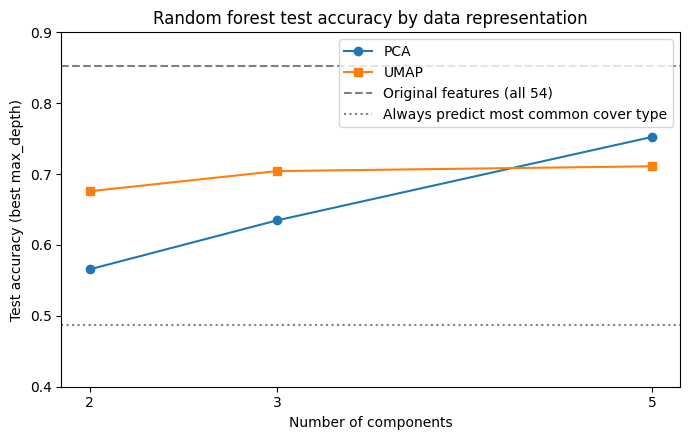

In [35]:
baseline = y_test.value_counts(normalize=True).max()
original_best = best.loc[best['representation'] == 'Original features', 'test_accuracy'].iloc[0]

plt.figure(figsize=(7, 4.5))
for rep, marker in [('PCA', 'o'), ('UMAP', 's')]:
    sub = best[best['representation'] == rep]
    plt.plot(sub['n_components'], sub['test_accuracy'], marker=marker, label=rep)
plt.axhline(original_best, color='gray', linestyle='--', label='Original features (all 54)')
plt.axhline(baseline, color='gray', linestyle=':', label='Always predict most common cover type')
plt.xticks([2, 3, 5])
plt.ylim(0.4, 0.9)
plt.xlabel('Number of components')
plt.ylabel('Test accuracy (best max_depth)')
plt.title('Random forest test accuracy by data representation')
plt.legend()
plt.tight_layout()
plt.show()

### Results and discussion

Best test accuracy for each data representation, using whichever `max_depth` scored highest (numbers from this run):

| Data given to the random forest | Best test accuracy |
|---|---|
| Original features (all 54) | 0.852 |
| PCA, 2 components | 0.566 |
| PCA, 3 components | 0.635 |
| PCA, 5 components | 0.752 |
| UMAP, 2 components | 0.676 |
| UMAP, 3 components | 0.698 |
| UMAP, 5 components | 0.711 |
| Always predicting the most common cover type (type 2) | 0.488 |

**The original features give the best accuracy.** Shrinking 54 features down to 5 or fewer throws away information that the random forest uses to tell cover types apart. Every reduced version still does much better than always guessing the most common cover type, so the components do keep useful structure.

**PCA is weak with only a few components.** Two components keep only 12.4% of the variance (17.0% for three, 23.7% for five). The variance is spread over many directions. Most of the 44 one-hot wilderness area and soil type columns are close to independent after scaling, which is why so many eigenvalues in the PCA section above are close to 1. PCA also picks the directions of largest variance, not the directions that separate the cover types, because it never sees the target.

**UMAP does better than PCA at 2 and 3 components.** UMAP is nonlinear and tries to keep each point's nearest neighbors close together. Points of the same cover type that were near each other in the full 54-feature space mostly stay near each other in 2 or 3 dimensions. **At 5 components PCA overtakes UMAP.** PCA keeps improving as components are added, because each new component brings back more of the original information. UMAP gains less from extra dimensions, because its layout is already built to fit the neighborhood structure into a small space. Test points are also placed into the UMAP embedding with `transform`, which is an approximation and can cost a bit of accuracy.

**Overfitting shows up when tree depth is unlimited.** Training accuracy is 1.000 in every case, far above test accuracy. For PCA with 2 components, deeper trees actually make test accuracy worse (0.566 at depth 5, 0.559 at depth 15, 0.525 with no limit). The cover types overlap heavily in two dimensions, so deep trees end up memorizing noise. With the original features, the deepest trees did best, because there is enough information to support the extra detail.

**Caveat about tuning:** `max_depth` was chosen by looking at test accuracy, so the best scores above are slightly optimistic. In practice the scaler, the PCA or UMAP step and the random forest would go into one `Pipeline`. Both `max_depth` and the number of components would be tuned with cross-validation on the training set only, and the test set would be used once at the very end. The UMAP numbers can also shift slightly if the notebook is run again.

## Best models on the full dataset

On the 30,000-row sample, the best setting for every data representation was a random forest with **no depth limit**. For both PCA and UMAP, **5 components** scored best. Those settings are now retrained and tested on all 581,012 rows:

- the original 54 features
- PCA with 5 components
- UMAP with 5 components

The setup is the same as before: a stratified 70% / 30% train/test split, and the scaler, PCA and UMAP are fit on the training rows only. The forests use `n_jobs=-2`, which uses every CPU core but one.

In [36]:
import time

# Train/test split on all 581,012 rows (70% / 30%, stratified by cover type)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

# Scaler fit on the training set only
scaler_full = StandardScaler().fit(X_train_full)
X_train_full_sc = scaler_full.transform(X_train_full)
X_test_full_sc = scaler_full.transform(X_test_full)
print('training rows:', len(X_train_full), '  test rows:', len(X_test_full))
print('accuracy from always predicting the most common cover type:',
      round(y_test_full.value_counts(normalize=True).max(), 3))

full_results = []

def evaluate_full(representation, Xtr, Xte):
    """Fit the best random forest setting (200 trees, no depth limit) and record accuracy and time."""
    start = time.time()
    rf = RandomForestClassifier(n_estimators=200, max_depth=None, n_jobs=-2, random_state=42)
    rf.fit(Xtr, y_train_full)
    full_results.append({
        'representation': representation,
        'train_accuracy': accuracy_score(y_train_full, rf.predict(Xtr)),
        'test_accuracy': accuracy_score(y_test_full, rf.predict(Xte)),
        'forest_seconds': round(time.time() - start, 1),
    })

training rows: 406708   test rows: 174304
accuracy from always predicting the most common cover type: 0.488


In [37]:
# Original features: all 54 scaled columns
evaluate_full('Original features (all 54)', X_train_full_sc, X_test_full_sc)

# PCA with 5 components, fit on the training set only
pca_full = PCA(n_components=5, random_state=42).fit(X_train_full_sc)
evaluate_full('PCA, 5 components', pca_full.transform(X_train_full_sc), pca_full.transform(X_test_full_sc))

pd.DataFrame(full_results).round(3)

,representation,train_accuracy,test_accuracy,forest_seconds
0,Original features (all 54),1.0,0.952,22.2
1,"PCA, 5 components",1.0,0.864,24.8


In [38]:
# UMAP with 5 components on the full training set.
# This is the slow part: about 18 minutes for ~400,000 rows. random_state makes UMAP use a single core.
start = time.time()
umap_full = umap.UMAP(n_components=5, random_state=42, compatibility_layout=True,
                      low_memory=True).fit(X_train_full_sc)
X_test_full_umap = umap_full.transform(X_test_full_sc)
print(f'UMAP fit and transform took {(time.time() - start) / 60:.1f} minutes')

evaluate_full('UMAP, 5 components', umap_full.embedding_, X_test_full_umap)
pd.DataFrame(full_results).round(3)

c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\owner\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


UMAP fit and transform took 16.8 minutes


,representation,train_accuracy,test_accuracy,forest_seconds
0,Original features (all 54),1.0,0.952,22.2
1,"PCA, 5 components",1.0,0.864,24.8
2,"UMAP, 5 components",1.0,0.861,31.2


### Full-dataset results and conclusion

Test accuracy on the 174,304 held-out rows (numbers from this run), next to the same settings on the 30,000-row sample:

| Data given to the random forest | 30,000-row sample | Full dataset |
|---|---|---|
| Original features (all 54) | 0.852 | **0.952** |
| PCA, 5 components | 0.752 | 0.864 |
| UMAP, 5 components | 0.711 | 0.861 |
| Always predicting the most common cover type (type 2) | 0.488 | 0.488 |

**More data helps every model a lot.** Accuracy rose by about 10 to 15 percentage points. A random forest with no depth limit splits the data into very small regions. With about 400,000 training rows, each region holds many more real examples, so the trees learn real patterns instead of memorizing a few points. The overfitting seen on the sample shrinks.

**The original features are still clearly best.** They score about 9 points higher than either reduced version. Compressing 54 features into 5 loses information that the forest uses, and more training data can't bring back information the components never kept.

**UMAP nearly catches up with PCA on the full data** (0.861 compared with 0.864, where the sample gave 0.711 compared with 0.752). With many more points, UMAP's nearest-neighbor graph is denser, so its embedding describes the data better, and test points are placed into it more accurately.

**Cost:** the random forest on the original features trained in well under a minute, and PCA added almost nothing. UMAP took about 18 minutes to fit on the 406,708 training rows, by far the slowest part, and it gave no accuracy gain here.

**Conclusion:** for predicting cover type with a random forest, dimension reduction does not pay off. The forest handles all 54 features easily, and there are far more rows than features. For this dataset, PCA and UMAP are more useful as tools to visualize the data in 2 or 3 dimensions, or for models that struggle with many features, such as k-nearest neighbors.